<a href="https://colab.research.google.com/github/GulshanKumarDhakad/MICROPLASTIC-DETECTION/blob/main/microplastic_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Microplastic Detection from Spectral Peaks (Random Forest)

**Goal:** given the strongest peak positions (in cm⁻¹) of a sample's spectrum (FTIR/Raman), classify it as
one of: `PE`, `PP`, `PS`, `PET`, `PVC`, `Nylon`, or `no_microplastic` (natural material).

**Notebook plan**
1. Setup & problem definition  ← *this part*
2. Build a realistic dataset (with noise, shifts, missing peaks, contaminants, batches)
3. Explore the data (EDA)
4. Feature engineering
5. Models + honest evaluation (baseline → RF → tuning)
6. Explainability (feature importance)
7. Save model + predict on new samples
8. Limitations / next steps

## 1. Setup

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams["figure.figsize"] = (9, 4)
pd.set_option("display.max_columns", 30)

## 2. Dataset

**Assumption (please verify):** peaks are IR/Raman wavenumbers in cm⁻¹. The reference peaks below are
*approximate* textbook values — check them against a library (e.g. SLoPP / open spectral libraries) or your lab
data before claiming results. If you have **real spectra**, replace this section with a loader; everything after
stays the same.

**Why simulate carefully?** A naive generator (fixed peaks + tiny noise) gives ~100 % accuracy that means nothing.
So each simulated sample gets:
- **Peak shift noise** (instrument precision) + a **batch-level calibration offset** (different days/instruments)
- **Missing peaks** (weak peaks not detected)
- **Extra contaminant peaks** (dyes, additives, organic residue)
- Only the **top 10** peaks kept, as in your original `Peak_1..Peak_10` format
- **`no_microplastic`** built from natural materials (cellulose, calcite, silica, protein)

In [ ]:
REF_PEAKS = {
    "PE":    [2915, 2848, 1470, 1462, 730, 719],
    "PP":    [2950, 2917, 2838, 1455, 1376, 1167, 998, 973],
    "PS":    [3060, 3026, 2920, 1601, 1493, 1452, 1028, 756, 698],
    "PET":   [1715, 1410, 1340, 1240, 1100, 1018, 872, 723],
    "PVC":   [2970, 2912, 1426, 1330, 1250, 958, 690, 615],
    "Nylon": [3300, 2930, 2860, 1640, 1540, 1260, 1200],
}
# natural look-alikes: each sample picks ONE of these materials
NATURAL = {
    "cellulose": [3330, 2900, 1430, 1370, 1160, 1030, 897],
    "calcite":   [1420, 875, 712],
    "silica":    [1080, 800, 460],
    "protein":   [3290, 1650, 1540, 1450, 1240],
}
N_PEAKS = 10
LABELS = list(REF_PEAKS) + ["no_microplastic"]

In [ ]:
def simulate_sample(label, batch_shift, rng, shift_sd=3.0, drop_p=0.15, max_extra=3):
    if label == "no_microplastic":
        base = np.array(NATURAL[rng.choice(list(NATURAL))], float)
    else:
        base = np.array(REF_PEAKS[label], float)

    peaks = base + batch_shift + rng.normal(0, shift_sd, len(base))   # shifts
    peaks = peaks[rng.random(len(base)) > drop_p]                      # missed peaks
    extras = rng.uniform(500, 3500, rng.integers(0, max_extra + 1))    # contaminants
    peaks = np.concatenate([peaks, extras])

    if len(peaks) > N_PEAKS:                                           # keep 10
        peaks = rng.choice(peaks, N_PEAKS, replace=False)
    peaks = np.sort(peaks)
    out = np.full(N_PEAKS, np.nan)                                     # NaN = no peak
    out[:len(peaks)] = peaks
    return out


def build_dataset(n_batches=40, per_class_per_batch=8, **kw):
    rows = []
    for b in range(n_batches):
        batch_shift = rng.normal(0, 3.0)        # instrument calibration offset
        for label in LABELS:
            for _ in range(per_class_per_batch):
                rows.append([b, label, *simulate_sample(label, batch_shift, rng, **kw)])
    cols = ["batch", "Label"] + [f"Peak_{i+1}" for i in range(N_PEAKS)]
    return pd.DataFrame(rows, columns=cols)

df = build_dataset()
df.to_csv("microplastics_simulated.csv", index=False)
print(df.shape)
df.head()

(2240, 12)


,batch,Label,Peak_1,Peak_2,Peak_3,Peak_4,Peak_5,Peak_6,Peak_7,Peak_8,Peak_9,Peak_10
0,0,PE,720.297672,727.007613,1457.061046,1473.735845,1830.242596,2912.794199,NaN,NaN,NaN,NaN
1,0,PE,631.411297,719.359564,730.764374,962.868476,1465.549502,1468.037503,2549.146860,2850.020404,2913.336274,NaN
2,0,PE,723.301068,732.762090,1437.099924,1460.472833,1469.377423,2847.694906,2996.779404,NaN,NaN,NaN
3,0,PE,721.950892,731.584938,919.390994,1465.528438,1471.570217,2206.223588,2849.264209,NaN,NaN,NaN
4,0,PE,720.402410,729.909496,1473.818986,2846.316658,2920.398975,3060.209220,NaN,NaN,NaN,NaN


## 3. Explore the data

In [ ]:
print(df["Label"].value_counts(), "\n")
peak_cols = [c for c in df.columns if c.startswith("Peak_")]
df["n_peaks"] = df[peak_cols].notna().sum(axis=1)
print("Missing values per peak column:\n", df[peak_cols].isna().sum())
df.groupby("Label")["n_peaks"].describe().round(2)

Label
PE                 320
PP                 320
PS                 320
PET                320
PVC                320
Nylon              320
no_microplastic    320
Name: count, dtype: int64 

Missing values per peak column:
 Peak_1        0
Peak_2        2
Peak_3       21
Peak_4       75
Peak_5      161
Peak_6      314
Peak_7      589
Peak_8     1008
Peak_9     1446
Peak_10    1852
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Label,,,,,,,,
Nylon,320.0,7.45,1.52,3.0,6.0,7.0,9.0,10.0
PE,320.0,6.60,1.44,3.0,6.0,7.0,8.0,9.0
PET,320.0,8.22,1.45,3.0,7.0,8.0,10.0,10.0
PP,320.0,8.13,1.44,4.0,7.0,8.0,9.0,10.0
PS,320.0,8.87,1.22,3.0,8.0,9.0,10.0,10.0
PVC,320.0,8.29,1.35,3.0,7.0,8.0,9.0,10.0
no_microplastic,320.0,5.35,2.03,1.0,4.0,5.0,7.0,10.0


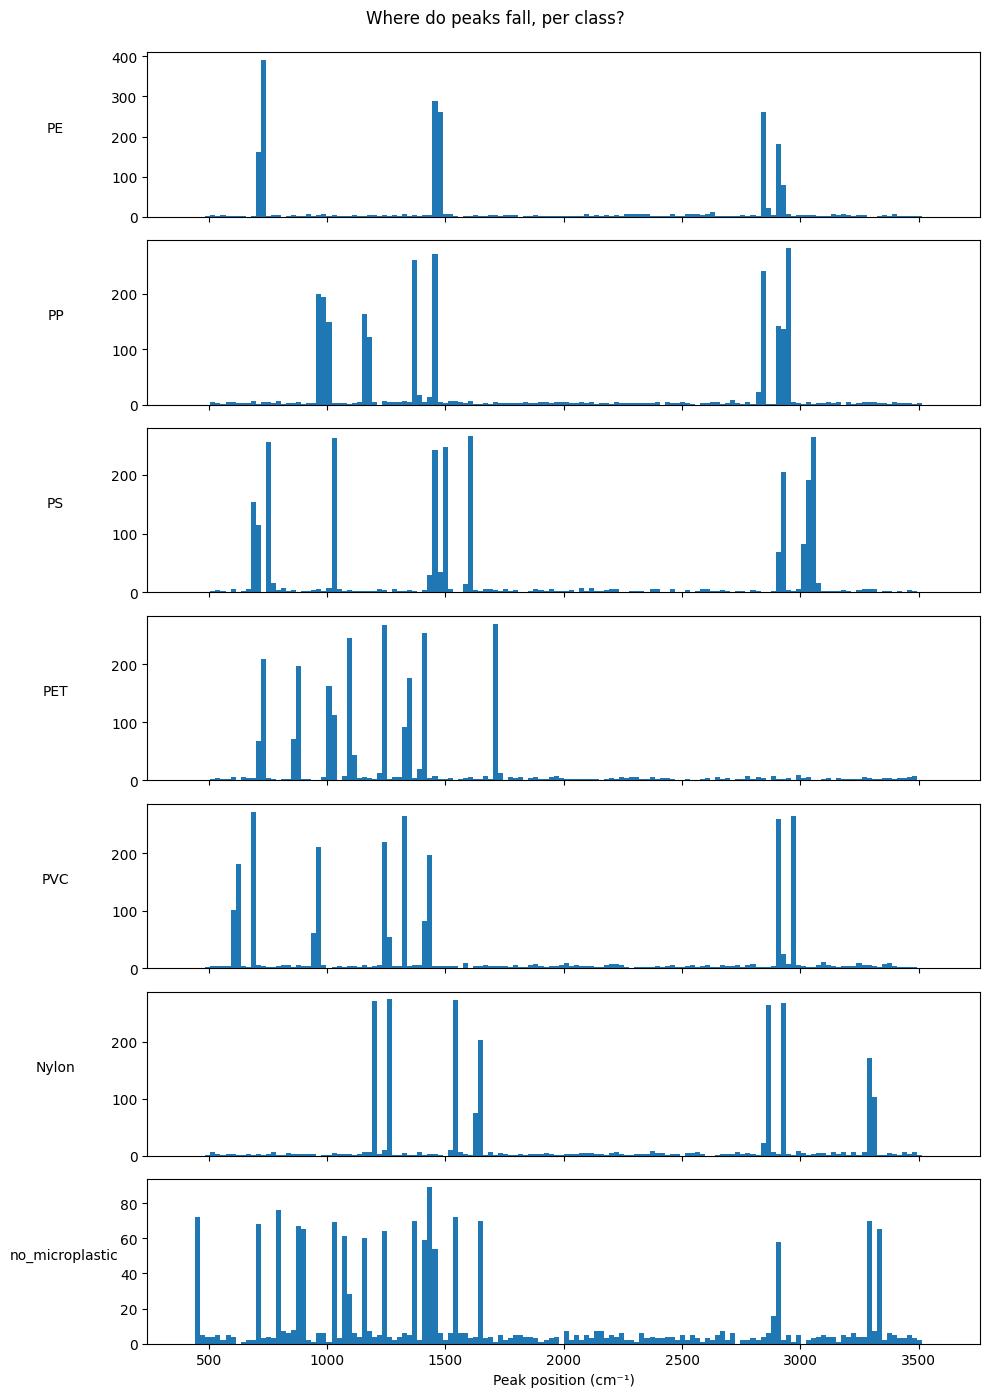

In [ ]:
fig, axes = plt.subplots(len(LABELS), 1, figsize=(10, 2*len(LABELS)), sharex=True)
for ax, lab in zip(axes, LABELS):
    vals = df.loc[df.Label == lab, peak_cols].to_numpy().ravel()
    ax.hist(vals[~np.isnan(vals)], bins=150, range=(400, 3600))
    ax.set_ylabel(lab, rotation=0, labelpad=40)
axes[-1].set_xlabel("Peak position (cm⁻¹)")
plt.suptitle("Where do peaks fall, per class?", y=0.995)
plt.tight_layout(); plt.show()

### What to notice
- Classes overlap (PE vs PP both have peaks near 2915; cellulose vs PS near 1030). That overlap is what makes this a real ML problem.
- `batch` is kept in the data on purpose: in step 5 we will split **by batch**, so the test set mimics *new instruments/days*,
  not just new rows from the same batches.

**Next (Part 2):** feature engineering (binned peak-presence vectors instead of raw `Peak_1..10`), a baseline, Random Forest with
batch-aware cross-validation, and a proper report.